# Unsupervised Learning - Dimensionality Reduction
## Non-linear methods for dimensionality reduction - Manifold learning

Follow:
- _Python Data Science Handbook_ [Chapter 5 In Depth: Manifold learning](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.10-Manifold-Learning.ipynb) (p.445-455)
- _Introduction to Machine Learning_ [Chapter 3](https://github.com/amueller/introduction_to_ml_with_python/blob/master/03-unsupervised-learning.ipynb) **Section 3.4.3 Manifold Learning with t-SNE** (p.165-170)


PCA reduces dimension by projection onto hyperplanes. It is a linear method.

An alternative is to perform Manifold learning, a non-linear technique.

A word of caution:
>... in practice manifold learning techniques tend to be finicky enough that they are rarely used for anything more than simple qualitative visualization of high-dimensional data.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

In [2]:
import mglearn

In [3]:
import warnings
warnings.filterwarnings(action='ignore')

## What is manifold learning?

Python Data Science Handbook Chapter 5: Manifold Learning

>We have seen how principal component analysis can be used in the dimensionality reduction task—reducing the number of features of a dataset while maintaining the essential relationships between the points. While PCA is flexible, fast, and easily interpretable, it does not perform so well when there are nonlinear relationships within the data; we will see some examples of these below.

>To address this deficiency, we can turn to a class of methods known as manifold learning—a class of unsupervised estimators that seeks to describe datasets as low-dimensional manifolds embedded in high-dimensional spaces. When you think of a manifold, I’d suggest imagining a sheet of paper: this is a two-dimensional object that lives in our familiar three-dimensional world, and can be bent or rolled in two dimensions. In the parlance of manifold learning, we can think of this sheet as a two-dimensional manifold embedded in three-dimensional space.

>Rotating, reorienting, or stretching the piece of paper in three-dimensional space doesn’t change the flat geometry of the paper: such operations are akin to linear embeddings. If you bend, curl, or crumple the paper, it is still a two-dimensional manifold, but the embedding into the three-dimensional space is no longer linear. Manifold learning algorithms would seek to learn about the fundamental two-dimensional nature of the paper, even as it is contorted to fill the three-dimensional space.


## MDS

From _Hands on Machine learning with scikit-learn_ Chapter 8 Dimensionality Reduction:
> Multidimensional Scaling (MDS) reduces dimensionality while trying to preserve the distances between the instances.

code from Python Data Science Handbook Chapter 5: [Manifold Learning](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.10-Manifold-Learning.ipynb)

In [4]:
def make_hello(N=1000, rseed=42):
    # Make a plot with "HELLO" text; save as PNG
    fig, ax = plt.subplots(figsize=(4, 1))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    ax.axis('off')
    ax.text(0.5, 0.4, 'HELLO', va='center', ha='center', weight='bold', size=85)
    fig.savefig('hello.png')
    plt.close(fig)

    # Open this PNG and draw random points from it
    from matplotlib.image import imread
    data = imread('hello.png')[::-1, :, 0].T
    rng = np.random.RandomState(rseed)
    X = rng.rand(4 * N, 2)
    i, j = (X * data.shape).astype(int).T
    mask = (data[i, j] < 1)
    X = X[mask]
    X[:, 0] *= (data.shape[0] / data.shape[1])
    X = X[:N]
    return X[np.argsort(X[:, 0])]

### Two representations of HELLO related by rotation

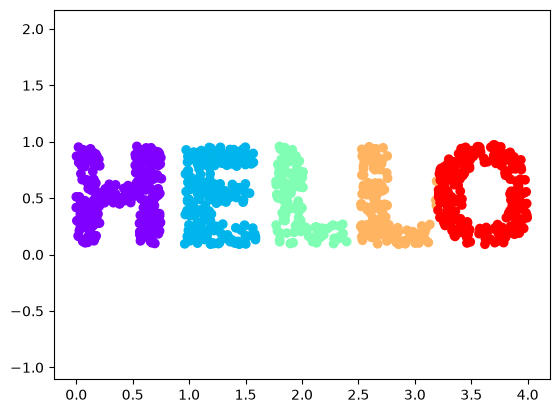

In [5]:
X = make_hello(1000)
colorize = dict(c=X[:, 0], cmap=mpl.colormaps['rainbow'].resampled(5))
plt.scatter(X[:, 0], X[:, 1], **colorize)
plt.axis('equal');

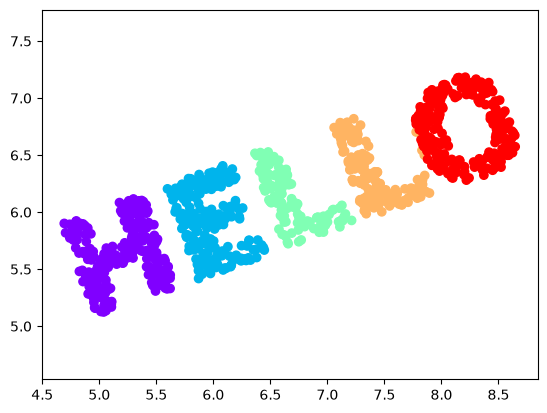

In [6]:
def rotate(X, angle):
    theta = np.deg2rad(angle)
    R = [[np.cos(theta), np.sin(theta)],
        [-np.sin(theta), np.cos(theta)]]
    return np.dot(X, R)

X2 = rotate(X, 20) + 5
plt.scatter(X2[:, 0], X2[:, 1], **colorize)
plt.axis('equal');

### Distances between points remain the same

In [7]:
from sklearn.metrics import pairwise_distances
D = pairwise_distances(X)
D.shape

(1000, 1000)

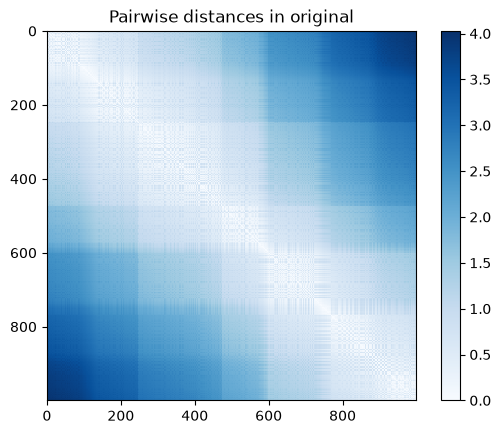

In [8]:
plt.imshow(D, zorder=2, cmap='Blues', interpolation='nearest')
plt.colorbar();
plt.title('Pairwise distances in original');

In [9]:
D2 = pairwise_distances(X2)
np.allclose(D, D2)

True

> This distance matrix gives us a representation of our data that is invariant to rotations and translations, but the visualization of the matrix is not entirely intuitive. In the representation presented in Figure 5-96, we have lost any visible sign of the interesting structure in the data: the “HELLO” that we saw before.

### Recovering HELLO from the distance matrix

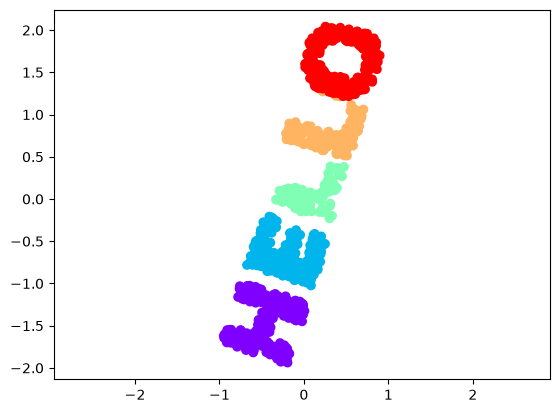

In [10]:
from sklearn.manifold import MDS
model = MDS(n_components=2, metric='precomputed', random_state=1)
out = model.fit_transform(D)
plt.scatter(out[:, 0], out[:, 1], **colorize)
plt.axis('equal');

>The MDS algorithm recovers one of the possible two-dimensional coordinate representations of our data, using only the N×N
 distance matrix describing the relationship between the data points.

### MDS as Manifold Learning
>The usefulness of this becomes more apparent when we consider the fact that distance matrices can be computed from data in any dimension. So, for example, instead of simply rotating the data in the two-dimensional plane, we can project it into three dimensions using the following function (essentially a three-dimensional generalization of the rotation matrix used earlier):

code from Python Data Science Handbook Chapter 5: [Manifold Learning](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.10-Manifold-Learning.ipynb)

In [11]:
def random_projection(X, dimension=3, rseed=42):
    assert dimension >= X.shape[1]
    rng = np.random.RandomState(rseed)
    C = rng.randn(dimension, dimension)
    e, V = np.linalg.eigh(np.dot(C, C.T))
    return np.dot(X, V[:X.shape[1]])

X3 = random_projection(X, 3)
X3.shape

(1000, 3)

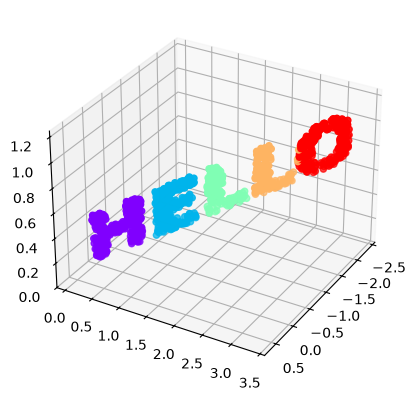

In [12]:
from mpl_toolkits import mplot3d
ax = plt.axes(projection='3d')
ax.scatter3D(X3[:, 0], X3[:, 1], X3[:, 2],
             **colorize)
ax.view_init(azim=30, elev=30)

>We can now ask the MDS estimator to input this three-dimensional data, compute the distance matrix, and then determine the optimal two-dimensional embedding for this distance matrix. The result recovers a representation of the original data

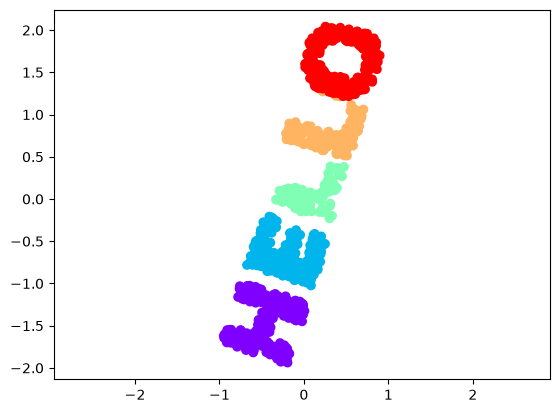

In [13]:
model = MDS(n_components=2, random_state=1)
out3 = model.fit_transform(X3)
plt.scatter(out3[:, 0], out3[:, 1], **colorize)
plt.axis('equal');

### Where MDS fails: Non-linear embeddings


In [14]:
def make_hello_s_curve(X):
    t = (X[:, 0] - 2) * 0.75 * np.pi
    x = np.sin(t)
    y = X[:, 1]
    z = np.sign(t) * (np.cos(t) - 1)
    return np.vstack((x, y, z)).T

XS = make_hello_s_curve(X)

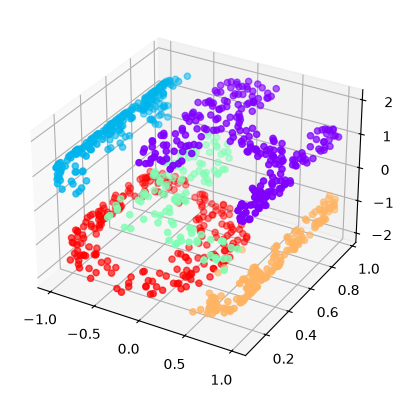

In [15]:
from mpl_toolkits import mplot3d
ax = plt.axes(projection='3d')
ax.scatter3D(XS[:, 0], XS[:, 1], XS[:, 2],
             **colorize);

> The fundamental relationships between the data points are still there, but this time the data has been transformed in a nonlinear way: it has been wrapped up into the shape of an “S.”

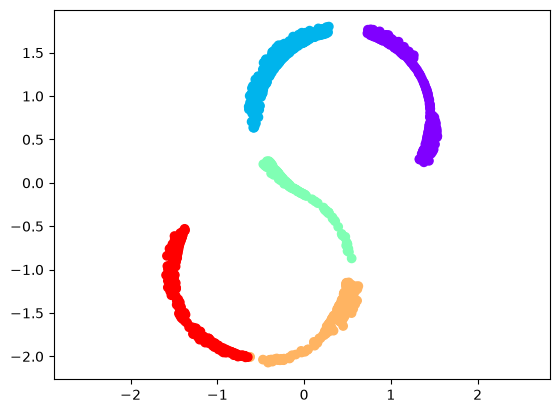

In [16]:
from sklearn.manifold import MDS
model = MDS(n_components=2, random_state=2)
outS = model.fit_transform(XS)
plt.scatter(outS[:, 0], outS[:, 1], **colorize)
plt.axis('equal');

### MDS tries to preserve distances between far away points

Instead of preserving all distances, preserving only distances to local points might help.

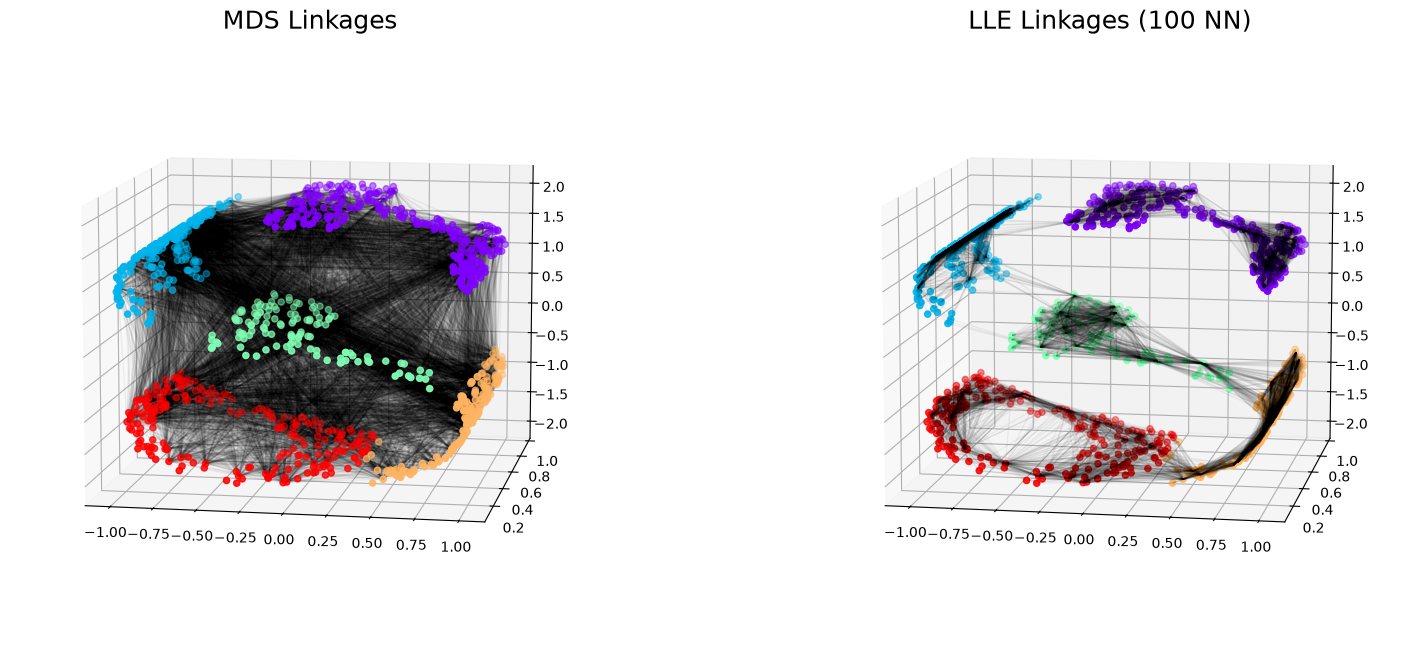

In [17]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from sklearn.neighbors import NearestNeighbors

# construct lines for MDS
rng = np.random.RandomState(42)
ind = rng.permutation(len(X))
lines_MDS = [(XS[i], XS[j]) for i in ind[:100] for j in ind[100:200]]

# construct lines for LLE
nbrs = NearestNeighbors(n_neighbors=100).fit(XS).kneighbors(XS[ind[:100]])[1]
lines_LLE = [(XS[ind[i]], XS[j]) for i in range(100) for j in nbrs[i]]
titles = ['MDS Linkages', 'LLE Linkages (100 NN)']

# plot the results
fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(projection='3d'))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0, wspace=0)

for axi, title, lines in zip(ax, titles, [lines_MDS, lines_LLE]):
    axi.scatter3D(XS[:, 0], XS[:, 1], XS[:, 2], **colorize);
    axi.add_collection(Line3DCollection(lines, lw=1, color='black',
                                        alpha=0.05))
    axi.view_init(elev=10, azim=-80)
    axi.set_title(title, size=18)

### Locally Linear Embedding LLE
>locally linear embedding (LLE): rather than preserving all distances, it instead tries to preserve only the distances between neighboring points.

code from Python Data Science Handbook Chapter 5: [Manifold Learning](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.10-Manifold-Learning.ipynb)

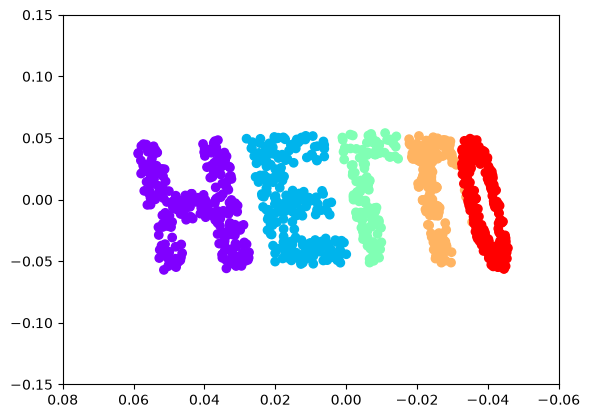

In [18]:
from sklearn.manifold import LocallyLinearEmbedding
model = LocallyLinearEmbedding(n_neighbors=100, n_components=2, method='modified',
                               eigen_solver='dense')
out = model.fit_transform(XS)

fig, ax = plt.subplots()
ax.scatter(out[:, 0], out[:, 1], **colorize)
ax.set_xlim(0.08, -0.06);
ax.set_ylim(-0.15, 0.15);

## Isomap

From _Hands on Machine learning with scikit-learn_ Chapter 8 Dimensionality Reduction:
> Isomap creates a graph by connecting each instance to its nearest neighbors, then reduces dimensionality while trying to preserve the geodesic distances between the instances. The geodesic distance between two nodes in a graph is the number of nodes on the shortest path between these nodes

code from Python Data Science Handbook Chapter 5: [Manifold Learning](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.10-Manifold-Learning.ipynb)

In [53]:
import json, html
import numpy as np
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import shortest_path, connected_components
from IPython.display import HTML, display

THEME = "auto"          # "auto" (follows OS setting), "light", or "dark"
K_RANGE = range(4, 31)  # values of k the slider can take

# ---------- 1. Data: 3D Swiss roll ----------
rng = np.random.default_rng(7)
N = 500
t = 1.5 * np.pi * (1 + 2 * rng.random(N))      # position along the roll
h = 21 * rng.random(N) - 10.5                   # height
X = np.column_stack([t * np.cos(t), h, t * np.sin(t)])

# Two points on adjacent layers: close in 3D, far along the manifold
A = int(np.argmin(np.abs(t - 9) + 0.3 * np.abs(h)))
cand = np.where(t - t[A] > 4)[0]
B = int(cand[np.argmin(np.linalg.norm(X[cand] - X[A], axis=1))])

# Nearest-neighbour order (enough for the largest k), used to draw the graph
E = np.linalg.norm(X[:, None] - X[None], axis=2)
nbr = np.argsort(E, axis=1)[:, 1:max(K_RANGE) + 1]


def classical_mds(D, d=2):
    """Classical MDS: double-centre squared distances, take top eigenvectors."""
    n = D.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    Bm = -0.5 * J @ (D ** 2) @ J
    vals, vecs = np.linalg.eigh(Bm)
    idx = np.argsort(vals)[::-1][:d]
    return vecs[:, idx] * np.sqrt(np.maximum(vals[idx], 0))


def isomap(k):
    # 2. k-NN graph, symmetrised, weighted by Euclidean distance
    G = kneighbors_graph(X, n_neighbors=k, mode="distance")
    G = G.maximum(G.T)
    n_comp, _ = connected_components(G, directed=False)

    # 3. Geodesic distances = all-pairs shortest paths (Dijkstra)
    D, pred = shortest_path(G, method="D", directed=False, return_predecessors=True)
    if np.isinf(D).any():
        D[np.isinf(D)] = D[np.isfinite(D)].max() * 1.5
    path, c = [], B
    while c >= 0:
        path.append(int(c))
        if c == A:
            break
        c = pred[A, c]

    # 4. Classical MDS on the geodesic distances
    Y = classical_mds(D, 2)
    if np.corrcoef(Y[:, 0], t)[0, 1] < 0:
        Y[:, 0] *= -1
    if np.corrcoef(Y[:, 1], h)[0, 1] > 0:
        Y[:, 1] *= -1

    # Residual variance: 1 - R^2 between geodesic and embedding distances
    sub = np.arange(0, N, 5)
    iu = np.triu_indices(len(sub), 1)
    dg = D[np.ix_(sub, sub)][iu]
    dy = np.linalg.norm(Y[sub, None] - Y[None, sub], axis=2)[iu]
    resid = 1 - np.corrcoef(dg, dy)[0, 1] ** 2

    return {"Y": np.round(Y, 3).ravel().tolist(), "path": path,
            "geo": round(float(D[A, B]), 2), "resid": round(float(resid), 4),
            "ncomp": int(n_comp)}


results = {k: isomap(k) for k in K_RANGE}

data = {
    "P": np.round(X, 3).ravel().tolist(), "T": np.round(t, 3).tolist(),
    "nbr": nbr.ravel().tolist(), "kmax": max(K_RANGE), "kmin": min(K_RANGE),
    "A": A, "B": B, "euc": round(float(E[A, B]), 2),
    "res": {str(k): v for k, v in results.items()},
}

# ---------- 5. Render the interactive page ----------
PAGE = r"""<!doctype html><html data-theme="__THEME__"><head><meta charset="utf-8">
<style>
:root{--text-primary:#1f1e1d;--text-secondary:#5f5e5a;--text-muted:#888780;--border-strong:rgba(31,30,29,.25);
--bg-accent:#E6F1FB;--text-accent:#185FA5;--border-accent:#85B7EB;--surface-1:#f5f4ef;--radius:8px}
@media (prefers-color-scheme:dark){:root:not([data-theme="light"]){--text-primary:#f1efe8;--text-secondary:#c2c0b6;--text-muted:#888780;
--border-strong:rgba(241,239,232,.25);--bg-accent:#0C447C;--text-accent:#B5D4F4;--border-accent:#378ADD;--surface-1:#2c2c2a}}
:root[data-theme="dark"]{--text-primary:#f1efe8;--text-secondary:#c2c0b6;--text-muted:#888780;--border-strong:rgba(241,239,232,.25);
--bg-accent:#0C447C;--text-accent:#B5D4F4;--border-accent:#378ADD;--surface-1:#2c2c2a}
html,body{margin:0;background:transparent}
body{font-family:system-ui,-apple-system,"Segoe UI",Roboto,sans-serif;color:var(--text-primary);padding:16px 4px;max-width:680px}
.pills{display:flex;gap:8px;flex-wrap:wrap;margin:0 0 12px}
.pill,button{font:inherit;font-size:13px;padding:4px 12px;border-radius:var(--radius);border:0.5px solid var(--border-strong);color:var(--text-secondary);cursor:pointer;background:transparent}
button{padding:6px 14px;color:var(--text-primary)}
button:hover,.pill:hover{background:var(--surface-1)}
.pill.on{background:var(--bg-accent);color:var(--text-accent);border-color:var(--border-accent)}
.row{display:flex;align-items:center;gap:12px;font-size:13px;color:var(--text-secondary);margin-top:10px;flex-wrap:wrap}
input[type=range]{accent-color:var(--text-accent)}
</style></head><body>
<div class="pills" id="pills"></div>
<div style="font-size:16px;font-weight:500;margin-bottom:4px" id="cap"></div>
<div style="font-size:13px;color:var(--text-muted);margin-bottom:8px" id="hint">Drag to rotate</div>
<canvas id="cv" style="width:100%;height:auto;display:block;cursor:grab;touch-action:none"></canvas>
<div class="row" id="read" style="min-height:20px"></div>
<div class="row">
<button id="prev">Back</button><button id="next">Next</button>
<span style="margin-left:auto">Neighbours k</span>
<input type="range" id="k" step="1" style="width:160px">
<span id="kv" style="min-width:20px;font-weight:500;color:var(--text-primary)"></span>
</div>
<script>
const D=__DATA__;
const N=D.T.length,W=680,H=380;let K=8,step=0,yaw=0.5,pitch=1.05,morph=0,animId=null;
const caps=["Sample a 3D Swiss roll","Connect each point to its k nearest neighbours","Shortest paths in the graph approximate geodesics","Classical MDS on geodesic distances unrolls it to 2D"];
const names=["1 Data","2 Graph","3 Geodesics","4 Embed"];
const P=[];for(let i=0;i<N;i++)P.push([D.P[3*i],D.P[3*i+1],D.P[3*i+2]]);
const T=D.T,A=D.A,B=D.B;
function col(t){const u=(t-4.71)/(14.14-4.71);const c=[[127,119,221],[29,158,117],[239,159,39]];const k=u<.5?0:1,f=u<.5?u*2:(u-.5)*2;const a=c[k],b=c[k+1];return `rgb(${a.map((x,i)=>Math.round(x+(b[i]-x)*f)).join(',')})`}
const C=T.map(col);
let edges,R,Y;
function build(){const s=new Set();edges=[];
for(let i=0;i<N;i++)for(let m=0;m<K;m++){const j=D.nbr[i*D.kmax+m];const a=Math.min(i,j),b=Math.max(i,j),key=a*N+b;if(!s.has(key)){s.add(key);edges.push([a,b])}}
R=D.res[String(K)];
let x0=1e9,x1=-1e9,y0=1e9,y1=-1e9;const raw=[];for(let i=0;i<N;i++){const p=[R.Y[2*i],R.Y[2*i+1]];raw.push(p);x0=Math.min(x0,p[0]);x1=Math.max(x1,p[0]);y0=Math.min(y0,p[1]);y1=Math.max(y1,p[1])}
const sc=Math.min(580/(x1-x0||1),300/(y1-y0||1));Y=raw.map(p=>[W/2+(p[0]-(x0+x1)/2)*sc,H/2+(p[1]-(y0+y1)/2)*sc])}
const cv=document.getElementById('cv'),dpr=window.devicePixelRatio||1;cv.width=W*dpr;cv.height=H*dpr;const ctx=cv.getContext('2d');ctx.scale(dpr,dpr);
function proj(p){const ca=Math.cos(yaw),sa=Math.sin(yaw),cb=Math.cos(pitch),sb=Math.sin(pitch);const x1=p[0]*ca+p[2]*sa,z1=-p[0]*sa+p[2]*ca;const y2=p[1]*cb-z1*sb,z2=p[1]*sb+z1*cb;return [W/2+x1*11,H/2+y2*11,z2]}
function draw(){const cs=getComputedStyle(document.documentElement);const muted=cs.getPropertyValue('--text-muted').trim();const prim=cs.getPropertyValue('--text-primary').trim();
ctx.clearRect(0,0,W,H);const Q=P.map(proj);const S2=Q.map((q,i)=>[q[0]+(Y[i][0]-q[0])*morph,q[1]+(Y[i][1]-q[1])*morph,q[2]]);
if(step>=1){ctx.strokeStyle=muted;ctx.globalAlpha=step===1?0.45:0.18;ctx.lineWidth=0.6;ctx.beginPath();for(const [i,j] of edges){ctx.moveTo(S2[i][0],S2[i][1]);ctx.lineTo(S2[j][0],S2[j][1])}ctx.stroke();ctx.globalAlpha=1}
const idx=[...Array(N).keys()];if(morph<1)idx.sort((a,b)=>S2[a][2]-S2[b][2]);
const fade=step>=2?0.45:1;for(const i of idx){ctx.globalAlpha=fade;ctx.fillStyle=C[i];ctx.beginPath();ctx.arc(S2[i][0],S2[i][1],3,0,6.283);ctx.fill()}ctx.globalAlpha=1;
if(step>=2){ctx.strokeStyle='#1D9E75';ctx.lineWidth=3;ctx.lineJoin='round';ctx.beginPath();R.path.forEach((k,n)=>{n?ctx.lineTo(S2[k][0],S2[k][1]):ctx.moveTo(S2[k][0],S2[k][1])});ctx.stroke();
if(morph<0.5){ctx.setLineDash([6,5]);ctx.strokeStyle='#D85A30';ctx.lineWidth=2;ctx.globalAlpha=1-morph*2;ctx.beginPath();ctx.moveTo(S2[A][0],S2[A][1]);ctx.lineTo(S2[B][0],S2[B][1]);ctx.stroke();ctx.setLineDash([]);ctx.globalAlpha=1}
for(const [k,l] of [[A,'A'],[B,'B']]){ctx.fillStyle='#534AB7';ctx.beginPath();ctx.arc(S2[k][0],S2[k][1],6,0,6.283);ctx.fill();ctx.fillStyle=prim;ctx.font='500 14px system-ui,sans-serif';ctx.fillText(l,S2[k][0]+9,S2[k][1]-8)}}}
const rd=document.getElementById('read');
function readout(){if(step<2){rd.innerHTML=step===1?`<span>${edges.length} edges, k = ${K}</span>`:`<span>${N} points, coloured by position along the roll</span>`;return}
let h=`<span style="color:#D85A30">Euclidean A to B: ${D.euc.toFixed(1)}</span><span style="color:#1D9E75">Geodesic A to B: ${R.geo.toFixed(1)}</span>`;
if(step===3){h+=`<span>Residual variance: ${R.resid.toFixed(3)}</span>`;if(R.ncomp>1)h+=`<span style="color:#D85A30">Graph has ${R.ncomp} components</span>`}rd.innerHTML=h}
const pills=document.getElementById('pills');names.forEach((n,i)=>{const b=document.createElement('button');b.className='pill';b.textContent=n;b.onclick=()=>go(i);pills.appendChild(b)});
function go(i){step=Math.max(0,Math.min(3,i));[...pills.children].forEach((b,j)=>b.classList.toggle('on',j===step));document.getElementById('cap').textContent=caps[step];document.getElementById('hint').textContent=step===3?'Points move to their 2D Isomap coordinates':'Drag to rotate';
const target=step===3?1:0;cancelAnimationFrame(animId);const st=morph,t0=performance.now();const tick=now=>{const f=Math.min(1,(now-t0)/900);const e=f<.5?2*f*f:1-Math.pow(-2*f+2,2)/2;morph=st+(target-st)*e;draw();if(f<1)animId=requestAnimationFrame(tick)};animId=requestAnimationFrame(tick);readout()}
document.getElementById('prev').onclick=()=>go(step-1);document.getElementById('next').onclick=()=>go(step+1);
let drag=null;cv.addEventListener('pointerdown',e=>{if(morph>0)return;drag=[e.clientX,e.clientY];cv.setPointerCapture(e.pointerId)});
cv.addEventListener('pointermove',e=>{if(!drag)return;yaw+=(e.clientX-drag[0])*0.01;pitch=Math.max(0.1,Math.min(1.5,pitch+(e.clientY-drag[1])*0.01));drag=[e.clientX,e.clientY];draw()});
cv.addEventListener('pointerup',()=>drag=null);
const ks=document.getElementById('k');ks.min=D.kmin;ks.max=D.kmax;ks.value=K;document.getElementById('kv').textContent=K;
ks.oninput=()=>{K=+ks.value;document.getElementById('kv').textContent=K;build();draw();readout()};
build();go(0);
</script></body></html>"""

page = PAGE.replace("__DATA__", json.dumps(data, separators=(",", ":"))).replace("__THEME__", THEME)
display(HTML(f'<iframe srcdoc="{html.escape(page, quote=True)}" '
             f'style="width:100%;max-width:700px;height:600px;border:none;background:transparent" '
             f'title="Isomap on a Swiss roll"></iframe>'))

### Labeled faces in the wild dataset

In [38]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=30)
faces.data.shape

(2370, 2914)

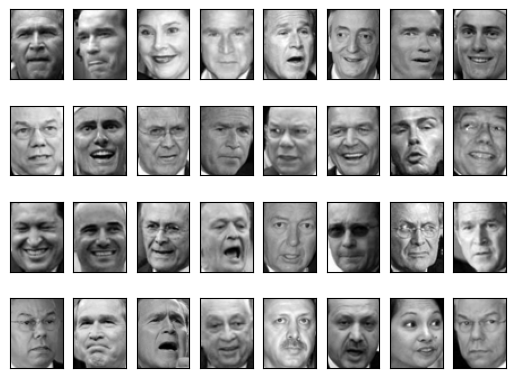

In [24]:
fig, ax = plt.subplots(4, 8, subplot_kw=dict(xticks=[], yticks=[]))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='gray')

### PCA needs many components - relationship might be non-linear

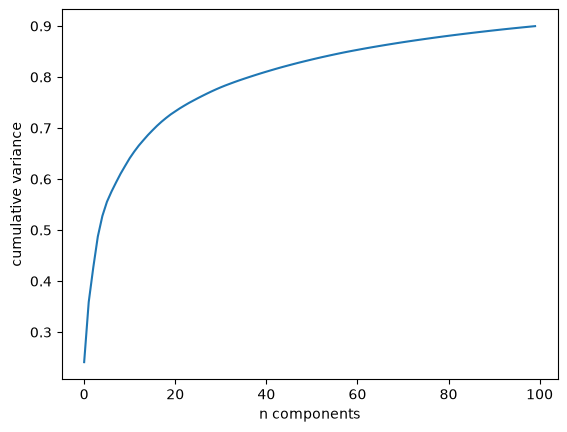

In [41]:
from sklearn.decomposition import PCA
model = PCA(100, svd_solver='randomized', random_state=88).fit(faces.data)
plt.plot(np.cumsum(model.explained_variance_ratio_))
plt.xlabel('n components')
plt.ylabel('cumulative variance');

### Isomap for visualization

In [42]:
from sklearn.manifold import Isomap
model = Isomap(n_components=2)
proj = model.fit_transform(faces.data)
proj.shape

(2370, 2)

In [43]:
from matplotlib import offsetbox

def plot_components(data, model, images=None, ax=None,
                    thumb_frac=0.05, zoom =1, cmap='gray'):
    ax = ax or plt.gca()
    
    proj = model.fit_transform(data)
    ax.plot(proj[:, 0], proj[:, 1], '.k')
    
    if images is not None:
        min_dist_2 = (thumb_frac * max(proj.max(0) - proj.min(0))) ** 2
        shown_images = np.array([2 * proj.max(0)])
        for i in range(data.shape[0]):
            dist = np.sum((proj[i] - shown_images) ** 2, 1)
            if np.min(dist) < min_dist_2:
                # don't show points that are too close
                continue
            shown_images = np.vstack([shown_images, proj[i]])
            imagebox = offsetbox.AnnotationBbox(
                offsetbox.OffsetImage(images[i], zoom=zoom,cmap=cmap),
                                      proj[i])
            ax.add_artist(imagebox)

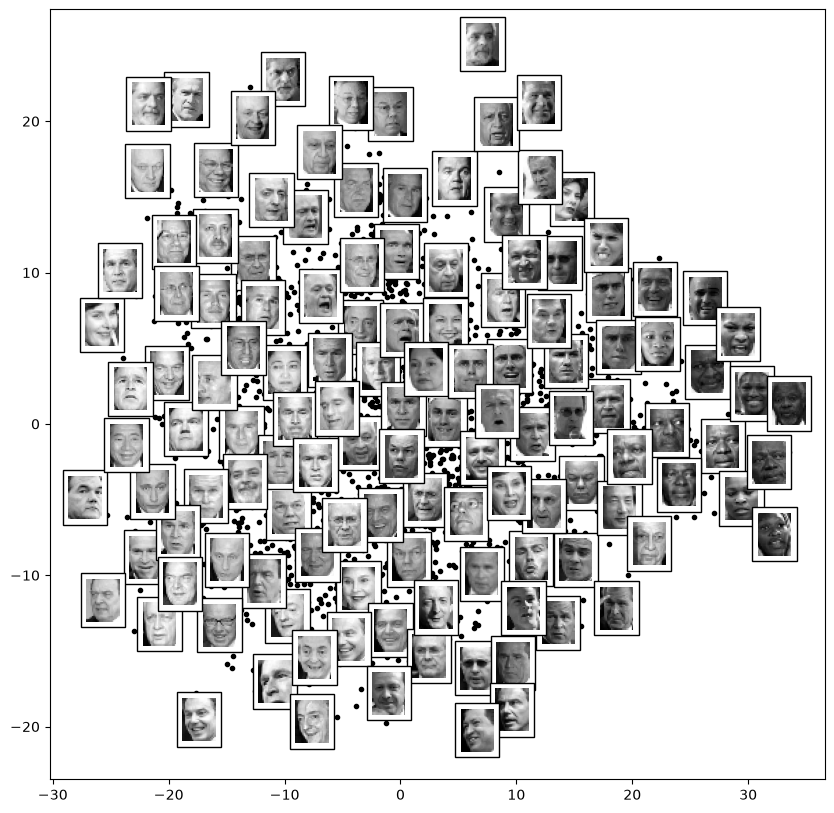

In [28]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_components(faces.data,
                model=Isomap(n_components=2),
                images=faces.images[:, ::2, ::2])

>The result is interesting: the first two Isomap dimensions seem to describe global image features: the overall darkness or lightness of the image from left to right, and the general orientation of the face from bottom to top. This gives us a nice visual indication of some of the fundamental features in our data.

>We could then go on to classify this data (perhaps using manifold features as inputs to the classification algorithm) as we did in In-Depth: Support Vector Machines.

### Isomap on digits

In [45]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

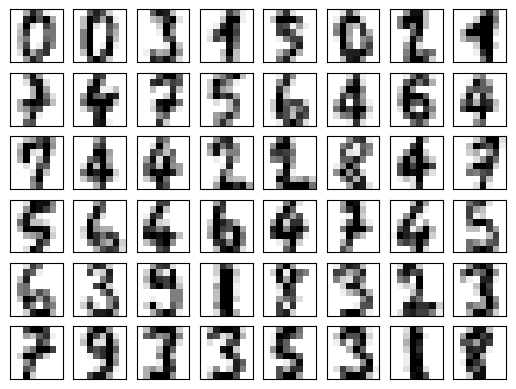

In [46]:
fig, ax = plt.subplots(6, 8, subplot_kw=dict(xticks=[], yticks=[]))
for i, axi in enumerate(ax.flat):
    axi.imshow(digits.data[30 * i].reshape(8, 8), cmap='gray_r')

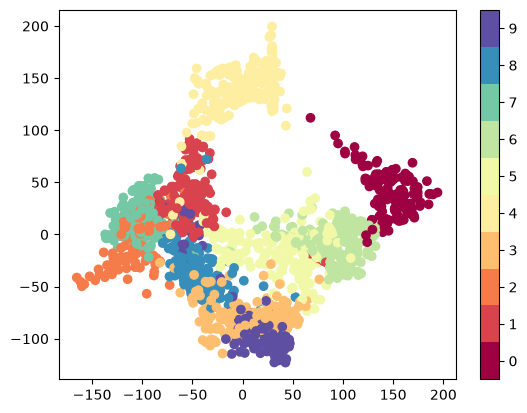

In [47]:
model = Isomap(n_components=2)
proj = model.fit_transform(digits.data)
plt.scatter(proj[:, 0], proj[:, 1], c=digits.target, cmap=mpl.colormaps['Spectral'].resampled(10))
plt.colorbar(ticks=range(10))
plt.clim(-0.5, 9.5);

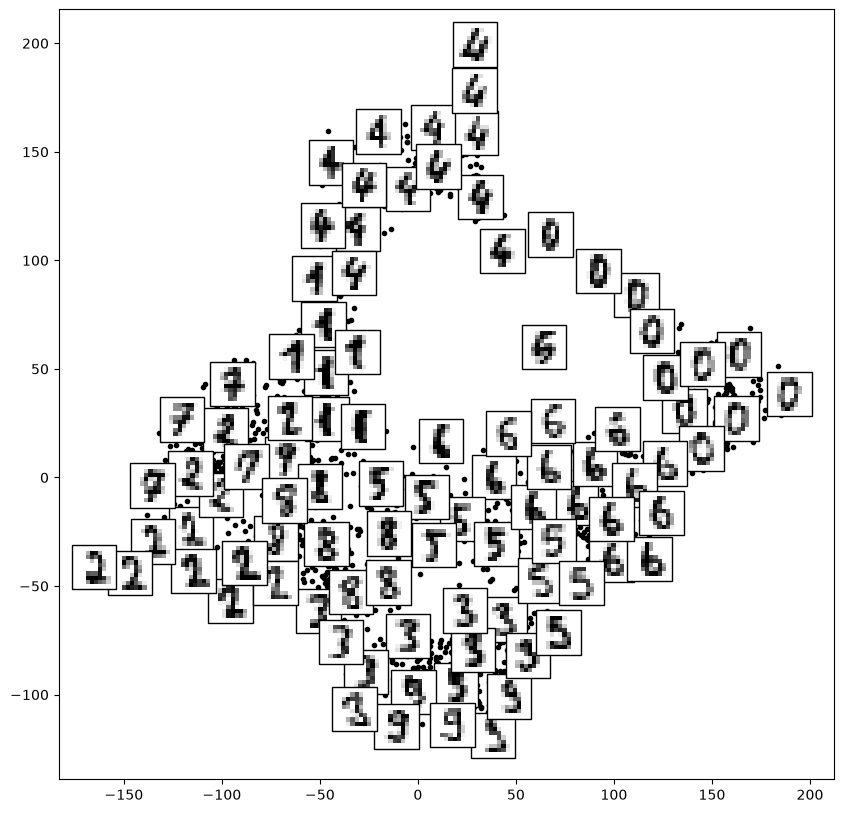

In [32]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_components(digits.data, model, images=digits.data.reshape((-1, 8, 8)),
                ax=ax, thumb_frac=0.05, zoom=3, cmap='gray_r')

## t-SNE
From _Hands on Machine learning with scikit-learn_ Chapter 8 Dimensionality Reduction:
>t-Distributed Stochastic Neighbor Embedding (t-SNE) reduces dimensionality while trying to keep similar instances close and dissimilar instances apart. It is mostly used for visualization, in particular to visualize clusters of instances in high-dimensional space (e.g., to visualize the MNIST images in 2D).

Code from Introduction to Machine Learning with Python [Chapter 3.4.1](https://github.com/amueller/introduction_to_ml_with_python/blob/master/03-unsupervised-learning.ipynb)

### t-SNE on Digits dataset

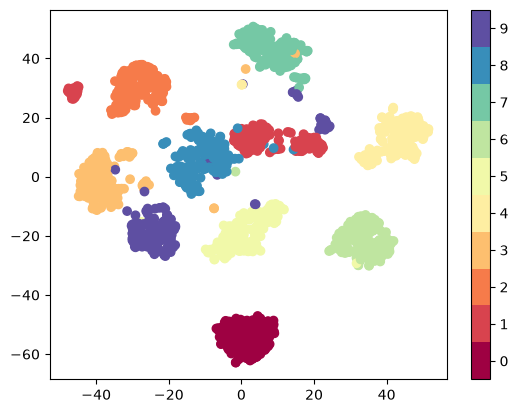

In [48]:
from sklearn.manifold import TSNE
tsne = TSNE(random_state=42)
proj = tsne.fit_transform(digits.data)
plt.scatter(proj[:, 0], proj[:, 1], c=digits.target, cmap=mpl.colormaps['Spectral'].resampled(10))
plt.colorbar(ticks=range(10))
plt.clim(-0.5, 9.5);

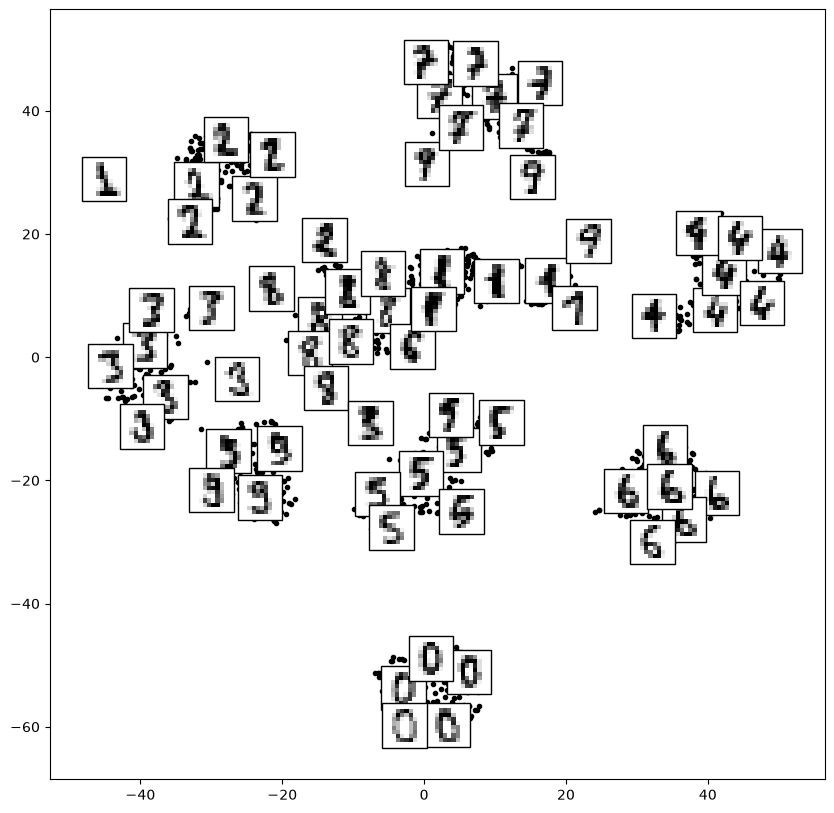

In [35]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_components(digits.data, tsne, images=digits.data.reshape((-1, 8, 8)),
                ax=ax, thumb_frac=0.05, zoom=3, cmap='gray_r')

## Summary

- For toy problems such as the S-curve we saw before, locally linear embedding (LLE) and its variants (especially modified LLE), perform very well. This is implemented in `sklearn.manifold.LocallyLinearEmbedding`.

- For high-dimensional data from real-world sources, LLE often produces poor results, and isometric mapping (Isomap) seems to generally lead to more meaningful embeddings. This is implemented in `sklearn.manifold.Isomap`.

- For data that is highly clustered, t-distributed stochastic neighbor embedding (t-SNE) seems to work very well, though can be very slow compared to other methods. This is implemented in `sklearn.manifold.TSNE`.